# 1. Аналитика оператора: продажи, тарифы, акции, отток

**Данные синтетические** — сгенерированы скриптом `src/generate_synthetic.py`, чтобы повторить
структуру данных мобильного оператора (абоненты, тарифы, салоны, потребление, продажи, акции).
Все расчёты делаются **SQL-запросами в Oracle** (`sql/03_analysis.sql`), здесь — визуализация и выводы.

Бизнес-вопросы:
1. Как меняются продажи в салонах?
2. Как абоненты используют услуги на разных тарифах?
3. Работают ли акции удержания — и как это доказать?
4. Где и почему абоненты уходят? Можно ли заметить уход заранее?

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})
GREEN, PURPLE, GREY = '#00B956', '#731982', '#9AA0A6'

from db import connect, named_queries, query_df
qs = named_queries(__import__('pathlib').Path('../sql/03_analysis.sql'))
conn = connect()
r = {k: query_df(conn, v) for k, v in qs.items()}
list(r)

['q1_sales_by_salon_month',
 'q2_tariff_usage',
 'q3_campaign_effect',
 'q4_cohort_retention',
 'q5_churn_by_salon',
 'q6_churn_signal']

## 1. Динамика продаж в салонах

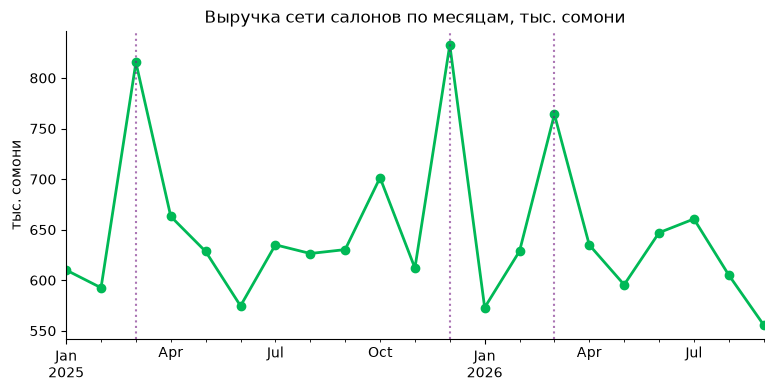

,"выручка, тыс. сомони"
salon,
"Душанбе, Шохмансур",1903.0
"Душанбе, Фирдавси",1854.0
"Душанбе, Сино",1812.0
"Душанбе, Исмоили Сомони",1788.0
"Худжанд, Панчшанбе",1288.0
"Худжанд, Центр",1260.0
"Куляб, Центр",659.0
"Хорог, Центр",630.0
"Турсунзаде, Центр",629.0


In [2]:
q1 = r['q1_sales_by_salon_month']
q1['month'] = pd.to_datetime(q1['month'])
net = q1.groupby('month')['revenue_tjs'].sum() / 1e3
ax = net.plot(color=GREEN, marker='o', lw=2)
ax.set(title='Выручка сети салонов по месяцам, тыс. сомони', xlabel='', ylabel='тыс. сомони')
for m in net.index[net.index.month.isin([3, 12])]:
    ax.axvline(m, color=PURPLE, ls=':', alpha=.6)
plt.show()
top = q1.groupby('salon')['revenue_tjs'].sum().sort_values(ascending=False) / 1e3
top.round(0).to_frame('выручка, тыс. сомони')

**Вывод.** Пики продаж приходятся на **декабрь и март** (Новый год и Навруз, пунктир) — к ним стоит
готовить запасы смартфонов и персонал. Основная выручка — у четырёх салонов Душанбе.

## 2. Использование услуг по тарифам

In [3]:
q2 = r['q2_tariff_usage'].set_index('tariff_name')
q2[['monthly_fee_tjs', 'arpu_tjs', 'avg_data_gb', 'data_package_used_pct', 'subscribers']]

,monthly_fee_tjs,arpu_tjs,avg_data_gb,data_package_used_pct,subscribers
tariff_name,,,,,
Безлимит,120.0,159.3,65.81,65.8,2241
Семейный,90.0,119.3,19.62,65.4,2241
Смарт,65.0,85.9,7.86,65.5,4891
Молодёжный,45.0,59.0,13.01,65.0,2992
Старт,35.0,45.8,1.94,64.7,4826


**Вывод.** На всех тарифах ARPU примерно на **30% выше абонентской платы**: абоненты докупают услуги сверх пакета.
При этом пакет интернета используется лишь на ~65%. Значит, люди платят сверху не за нехватку
трафика, а за другие услуги, и апсейл стоит строить на дополнительных сервисах, а не на объёме ГБ.

## 3. Эффективность акций удержания

In [4]:
from scipy import stats
q3 = r['q3_campaign_effect']
rows = []
for name, g in q3.groupby('campaign_name', sort=False):
    t = g[g.group_type == 'TARGET'].iloc[0]; c = g[g.group_type == 'CONTROL'].iloc[0]
    table = [[t.churned_3m, t.contacted - t.churned_3m], [c.churned_3m, c.contacted - c.churned_3m]]
    _, p, _, _ = stats.chi2_contingency(table)
    rows.append({'акция': name, 'отток TARGET, %': t.churn_3m_pct, 'отток CONTROL, %': c.churn_3m_pct,
                 'эффект, п.п.': round(t.churn_3m_pct - c.churn_3m_pct, 1), 'p-value': f'{p:.1e}'})
pd.DataFrame(rows)

,акция,"отток TARGET, %","отток CONTROL, %","эффект, п.п.",p-value
0,Осенний бонус +5 ГБ,21.4,30.3,-8.9,5.2e-04
1,Навруз: скидка 30% на 3 месяца,18.3,30.0,-11.7,1.7e-07


**Вывод.** Обе акции снижают отток за 3 месяца примерно на **9–12 п.п.** относительно контрольной группы,
различие статистически значимо (χ², p ≪ 0,01). Контрольная группа выбрана случайно, поэтому
разницу можно считать именно эффектом акции, а не особенностью выбранных абонентов.

## 4. Где уходят абоненты и можно ли это заметить заранее

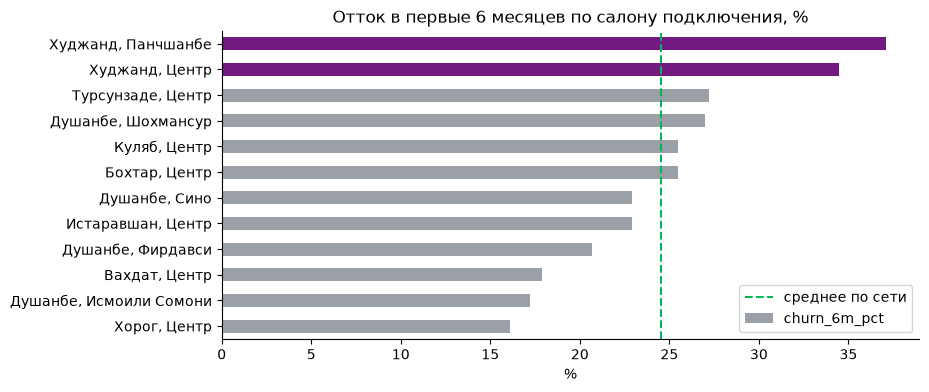

In [5]:
q5 = r['q5_churn_by_salon'].sort_values('churn_6m_pct')
colors = [PURPLE if v > 1.3 else GREY for v in q5.vs_network_avg]
ax = q5.plot.barh(x='salon', y='churn_6m_pct', color=colors, legend=False)
ax.axvline(q5.churn_6m_pct.mean(), color=GREEN, ls='--', label='среднее по сети')
ax.set(title='Отток в первые 6 месяцев по салону подключения, %', ylabel='', xlabel='%'); ax.legend()
plt.show()

In [6]:
q4 = r['q4_cohort_retention'].set_index('cohort')
q4

,activated,alive_3m_pct,alive_6m_pct,alive_12m_pct
cohort,,,,
2025-Q1,1757,86.9,75.1,62.2
2025-Q2,2585,86.6,77.0,61.0
2025-Q3,3058,85.2,74.8,60.1
2025-Q4,3514,85.9,74.8,NaN
2026-Q1,3819,86.4,75.3,NaN


In [7]:
q6 = r['q6_churn_signal'].set_index('segment')
q6

,rows_cnt,avg_data_trend,avg_topup_trend,avg_active_days
segment,,,,
Останется,124396,1.01,1.00,26.9
Уйдёт в след. месяце,5548,0.74,0.77,20.7


**Выводы.**
* Два салона в **Худжанде** «приводят» абонентов, которые уходят в 1,4–1,5 раза чаще среднего по сети.
  Это повод проверить качество подключения там (навязанный тариф? неверные ожидания клиента?).
* Когорты стабильны: через 6 месяцев остаётся ~75% подключившихся, через год ~61%.
* **Ранний сигнал:** за месяц до ухода трафик и пополнения падают в среднем на ~25%, активных дней
  меньше на 6. Это можно ловить автоматически — см. ноутбук 2 с моделью.

**Рекомендации:** (1) аудит подключений в салонах Худжанда; (2) масштабировать акции удержания —
эффект доказан на контрольной группе; (3) ежемесячно отбирать абонентов с падением потребления
для превентивного предложения.